# Workforce Under Automation: Exploratory and Unsupervised Analysis

**DATS 6103 · Fall 2026**  
**Team:** Mak Trnka, Galileo Frank Perricone, and Miguel Sanchez Zanella

## Purpose
This notebook looks at how automation exposure varies across industries and job roles, how categorical predictors relate to the layoff risk label, and whether profiles and job roles form natural groups using K-means clustering. The clusters are built without the risk label.

> **Note:** The profiles and labels in this dataset are synthetic. Findings describe this dataset only and should not be interpreted as conclusions about real workers or actual layoffs.

## Notebook outline
1. Load the data
2. Compare industries and job roles
3. Categorical predictors and layoff risk
4. K-means clustering on individual profiles
5. K-means clustering on job roles

## 1. Load the data
Keep `ai-impact-jobs-layoff-risk-dataset.csv` in the same folder as this notebook, or update the path in the loading cell.

### Imports
All libraries used in this notebook are imported here.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.stats import chi2_contingency

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

### Load the dataset and preview the first rows

In [ ]:
df = pd.read_csv("ai-impact-jobs-layoff-risk-dataset.csv")
df.head()

,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


## 2. Compare industries and job roles

### Automation and AI adoption by industry
The first heatmap shows average tasks automated %, routine task %, weekly AI usage hours and AI training hours for each industry. Colours are scaled within each measure; the numbers are the actual averages. The second heatmap shows the share of profiles at each AI adoption level within each industry (each column sums to 1).

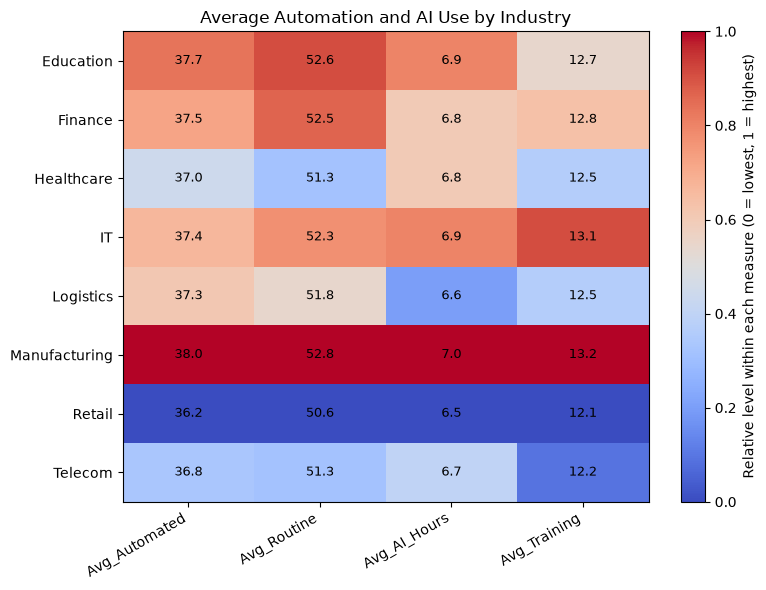

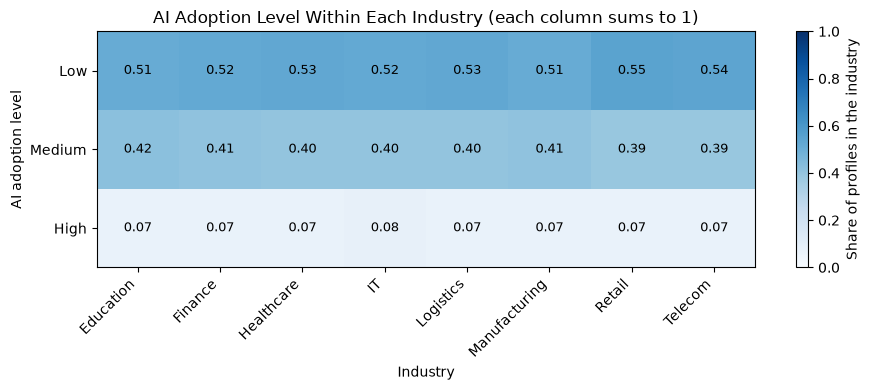

In [ ]:
# --- Heatmap 1: average exposure by industry ---
industry_summary = df.groupby("Industry").agg(
    Avg_Automated=("Tasks_Automated_Percentage", "mean"),
    Avg_Routine=("Routine_Task_Percentage", "mean"),
    Avg_AI_Hours=("AI_Usage_Hours_Per_Week", "mean"),
    Avg_Training=("AI_Training_Hours", "mean")
).round(1)

# Scale each column 0–1 so colours are comparable across measures
colour_values = (industry_summary - industry_summary.min()) / (industry_summary.max() - industry_summary.min())

fig, ax = plt.subplots(figsize=(8, 0.5 * len(industry_summary) + 2))
image = ax.imshow(colour_values, cmap="coolwarm", vmin=0, vmax=1, aspect="auto")

ax.set_xticks(range(len(industry_summary.columns)))
ax.set_xticklabels(industry_summary.columns, rotation=30, ha="right")
ax.set_yticks(range(len(industry_summary.index)))
ax.set_yticklabels(industry_summary.index)

for row in range(len(industry_summary.index)):
    for col in range(len(industry_summary.columns)):
        ax.text(col, row, f"{industry_summary.iloc[row, col]:.1f}",
                ha="center", va="center", fontsize=9)

fig.colorbar(image, ax=ax, label="Relative level within each measure (0 = lowest, 1 = highest)")
ax.set_title("Average Automation and AI Use by Industry")
plt.tight_layout()
plt.show()

# --- Heatmap 2: share of each AI adoption level within each industry ---
adoption_share = pd.crosstab(
    df["Industry"],
    df["AI_Adoption_Level"],
    normalize="index"
).round(2).reindex(columns=["Low", "Medium", "High"]).T

fig, ax = plt.subplots(figsize=(0.8 * len(adoption_share.columns) + 3, 4))
image = ax.imshow(adoption_share, cmap="Blues", vmin=0, vmax=1, aspect="auto")

ax.set_xticks(range(len(adoption_share.columns)))
ax.set_xticklabels(adoption_share.columns, rotation=45, ha="right")
ax.set_yticks(range(len(adoption_share.index)))
ax.set_yticklabels(adoption_share.index)

for row in range(len(adoption_share.index)):
    for col in range(len(adoption_share.columns)):
        ax.text(col, row, f"{adoption_share.iloc[row, col]:.2f}",
                ha="center", va="center", fontsize=9)

fig.colorbar(image, ax=ax, label="Share of profiles in the industry")
ax.set_xlabel("Industry")
ax.set_ylabel("AI adoption level")
ax.set_title("AI Adoption Level Within Each Industry (each column sums to 1)")
plt.tight_layout()
plt.show()

### Automation exposure by job role
Average routine task % and tasks automated % for each job role, sorted from most to least automated.

In [ ]:
# Average exposure by job role
role_exposure = df.groupby("Job_Role").agg(
    Number_of_Records=("Industry", "size"),
    Average_Routine_Tasks=("Routine_Task_Percentage", "mean"),
    Average_Tasks_Automated=("Tasks_Automated_Percentage", "mean")
).round(1).sort_values("Average_Tasks_Automated", ascending=False)

display(role_exposure)

,Number_of_Records,Average_Routine_Tasks,Average_Tasks_Automated
Job_Role,,,
Operator,858,53.3,38.6
Accountant,821,53.5,38.5
Academic Coordinator,819,53.3,38.3
Production Supervisor,806,52.9,38.0
Dispatcher,788,52.6,37.9
Software Engineer,829,52.5,37.7
Research Assistant,818,52.9,37.7
Health Analyst,772,51.8,37.6
Auditor,813,52.5,37.5


### Routine work vs. automation by job role
Each point is one job role, placed by its average routine task % and tasks automated %, and coloured by its most frequent `Layoff_Risk` label (green = Low, orange = Medium, red = High).

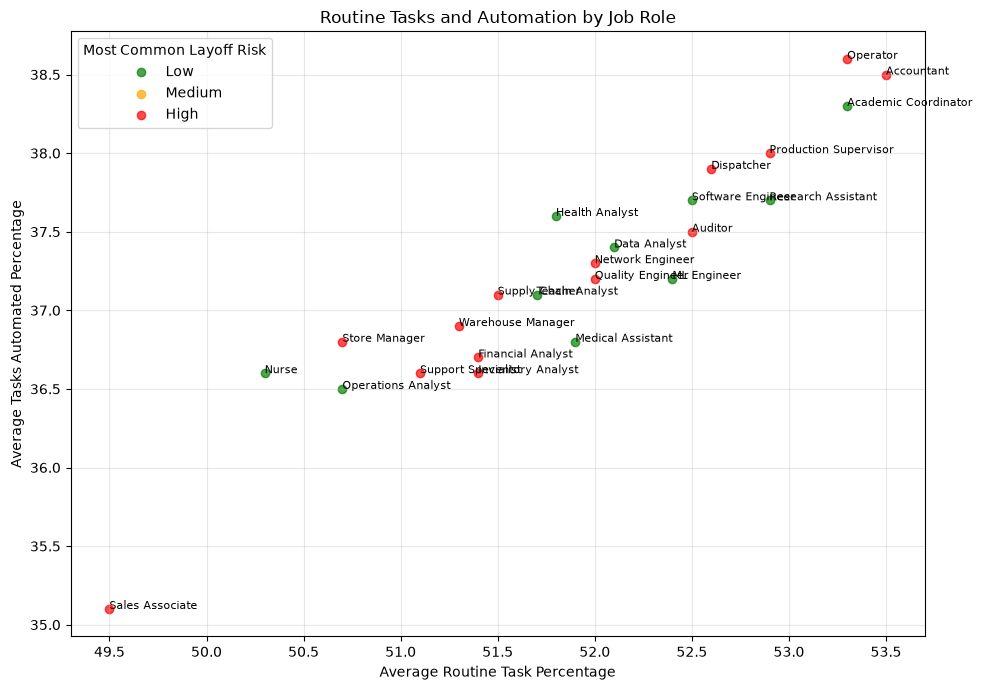

In [ ]:
most_common_risk = df.groupby("Job_Role")["Layoff_Risk"].agg(
    lambda values: values.value_counts().idxmax()
)

role_exposure["Most_Common_Risk"] = most_common_risk

risk_colors = {
    "Low": "green",
    "Medium": "orange",
    "High": "red"
}

plt.figure(figsize=(10, 7))

for risk, color in risk_colors.items():
    group = role_exposure[role_exposure["Most_Common_Risk"] == risk]

    plt.scatter(
        group["Average_Routine_Tasks"],
        group["Average_Tasks_Automated"],
        color=color,
        label=risk,
        alpha=0.7
    )

    for job_role, row in group.iterrows():
        plt.annotate(
            job_role,
            (row["Average_Routine_Tasks"], row["Average_Tasks_Automated"]),
            fontsize=8
        )

plt.xlabel("Average Routine Task Percentage")
plt.ylabel("Average Tasks Automated Percentage")
plt.title("Routine Tasks and Automation by Job Role")
plt.legend(title="Most Common Layoff Risk")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Categorical predictors and layoff risk
The first heatmap gives one score per categorical predictor (Cramér's V, from 0 = no association to 1 = perfect association) for how strongly it is linked to `Layoff_Risk`. It shows strength, not direction.

The heatmaps that follow show, for each level of each categorical predictor, the share of profiles labelled Low, Medium and High (each row sums to 1). Levels are sorted with the most High-risk at the top. Colour scales fit each plot, so compare the numbers rather than the colours across plots.

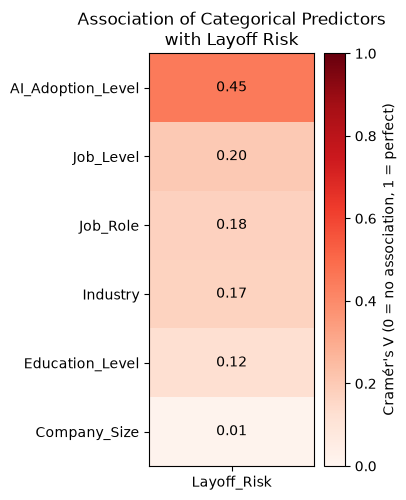

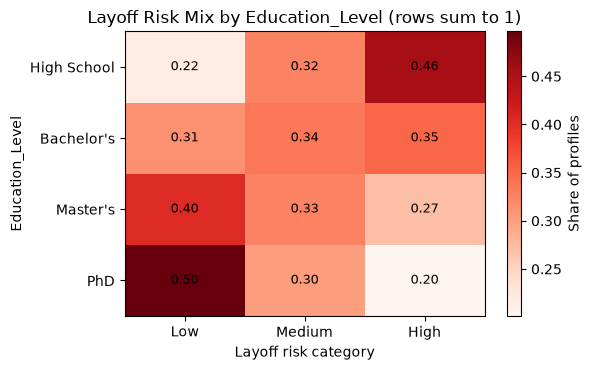

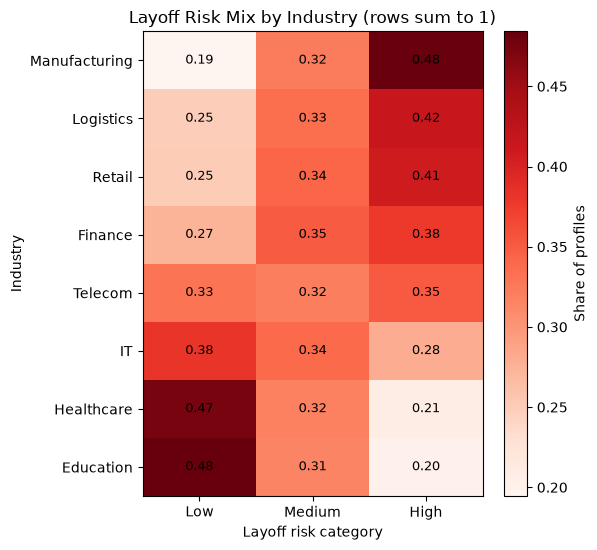

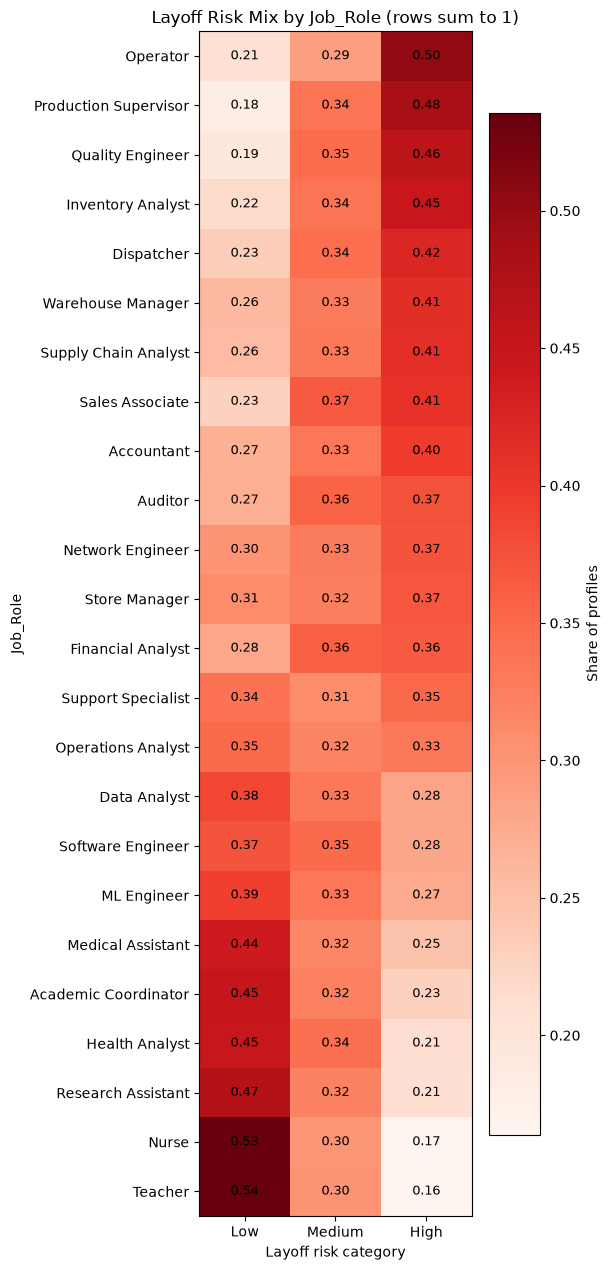

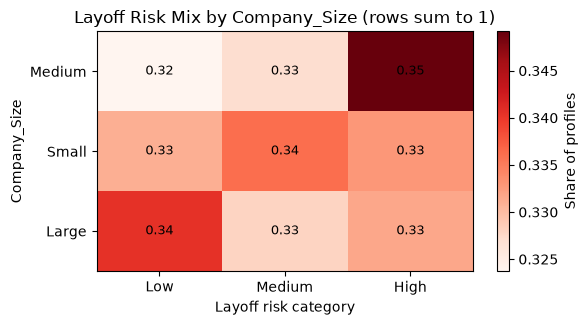

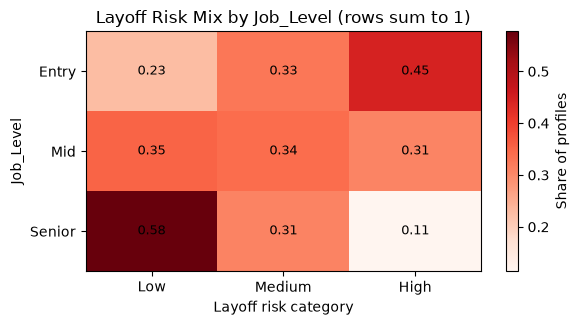

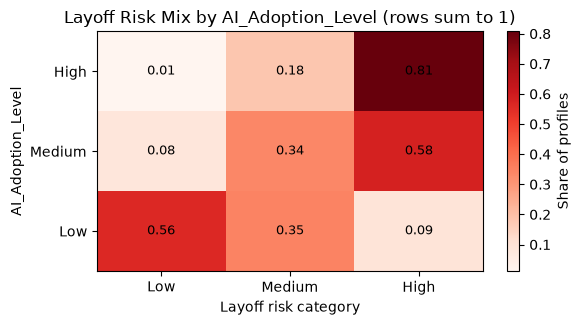

In [ ]:
categorical_features = [
    col for col in [
        "Education_Level",
        "Industry",
        "Job_Role",
        "Company_Size",
        "Job_Level",
        "AI_Adoption_Level"
    ]
    if col in df.columns
]
risk_order = ["Low", "Medium", "High"]

def cramers_v(x, y):
    data = pd.DataFrame({"x": x, "y": y}).dropna()
    table = pd.crosstab(data["x"], data["y"])

    if min(table.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    denominator = n * min(table.shape[0] - 1, table.shape[1] - 1)

    return np.sqrt(chi2 / denominator)

# --- Heatmap 1: strength of association with Layoff_Risk (Cramér's V) ---
risk_association = pd.DataFrame(
    {"Layoff_Risk": [cramers_v(df[feature], df["Layoff_Risk"]) for feature in categorical_features]},
    index=categorical_features
).sort_values("Layoff_Risk", ascending=False)

fig, ax = plt.subplots(figsize=(4, 0.6 * len(risk_association) + 1.5))
image = ax.imshow(risk_association, cmap="Reds", vmin=0, vmax=1, aspect="auto")

ax.set_xticks([0])
ax.set_xticklabels(["Layoff_Risk"])
ax.set_yticks(range(len(risk_association.index)))
ax.set_yticklabels(risk_association.index)

for row in range(len(risk_association.index)):
    ax.text(0, row, f"{risk_association.iloc[row, 0]:.2f}",
            ha="center", va="center", fontsize=10)

fig.colorbar(image, ax=ax, label="Cramér's V (0 = no association, 1 = perfect)")
ax.set_title("Association of Categorical Predictors\nwith Layoff Risk")
plt.tight_layout()
plt.show()

# --- Heatmaps 2+: share of Low / Medium / High risk within each category level ---
for feature in categorical_features:
    risk_share = pd.crosstab(
        df[feature],
        df["Layoff_Risk"],
        normalize="index"
    ).reindex(columns=risk_order).sort_values("High", ascending=False)

    fig, ax = plt.subplots(figsize=(6, 0.45 * len(risk_share) + 2))
    image = ax.imshow(risk_share, cmap="Reds", aspect="auto")

    ax.set_xticks(range(len(risk_order)))
    ax.set_xticklabels(risk_order)
    ax.set_yticks(range(len(risk_share.index)))
    ax.set_yticklabels(risk_share.index)

    for row in range(len(risk_share.index)):
        for col in range(len(risk_order)):
            ax.text(col, row, f"{risk_share.iloc[row, col]:.2f}",
                    ha="center", va="center", fontsize=9)

    fig.colorbar(image, ax=ax, label="Share of profiles")
    ax.set_xlabel("Layoff risk category")
    ax.set_ylabel(feature)
    ax.set_title(f"Layoff Risk Mix by {feature} (rows sum to 1)")
    plt.tight_layout()
    plt.show()

## 4. K-means clustering on individual profiles
Clusters every profile using three standardized features: routine task %, tasks automated % and creativity requirement. The silhouette score is reported for 2 to 6 clusters to help choose the number of clusters. It ranges from −1 to 1, and higher means better-separated clusters.

In [ ]:
features = [
    "Routine_Task_Percentage",
    "Tasks_Automated_Percentage",
    "Creativity_Requirement"
]

# Prepare and scale the three predictors
X = df[features].apply(pd.to_numeric, errors="coerce")
X = SimpleImputer(strategy="median").fit_transform(X)
X_scaled = StandardScaler().fit_transform(X)

# Compare a few possible numbers of clusters
for k in range(2, 7):
    clusters = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    score = silhouette_score(X_scaled, clusters)
    print(f"{k} clusters: silhouette score = {score:.3f}")

2 clusters: silhouette score = 0.546
3 clusters: silhouette score = 0.459
4 clusters: silhouette score = 0.398
5 clusters: silhouette score = 0.362
6 clusters: silhouette score = 0.342


## 5. K-means clustering on job roles
Each job role is summarized by its average routine task %, creativity requirement and tasks automated %, so each data point is one job role rather than one profile.

### Choosing the number of clusters
Silhouette scores for 2 to 5 clusters. The number of clusters with the highest score (`best_k`) is used in the next two cells.

In [ ]:
numeric_predictors = [
    "Routine_Task_Percentage",
    "Creativity_Requirement",
    "Tasks_Automated_Percentage",
]

# One row per job role, using its average numeric values
role_data = df.groupby("Job_Role")[numeric_predictors].mean()

# Prepare and scale the role averages
X = SimpleImputer(strategy="median").fit_transform(role_data)
X_scaled = StandardScaler().fit_transform(X)

# Calculate and print the silhouette score for each cluster count
scores = {}

for k in range(2, min(6, len(role_data))):
    labels = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    ).fit_predict(X_scaled)

    scores[k] = silhouette_score(X_scaled, labels)
    print(f"{k} clusters: silhouette score = {scores[k]:.3f}")

best_k = max(scores, key=scores.get)
print(f"\nBest number of clusters: {best_k}")
print(f"Best silhouette score: {scores[best_k]:.3f}")

2 clusters: silhouette score = 0.477
3 clusters: silhouette score = 0.475
4 clusters: silhouette score = 0.405
5 clusters: silhouette score = 0.422

Best number of clusters: 2
Best silhouette score: 0.477


### Job role clusters on a 2D map
Fits K-means with `best_k` clusters, then uses PCA to project the three averages onto two dimensions for plotting. Points are coloured by cluster and labelled with the job role.

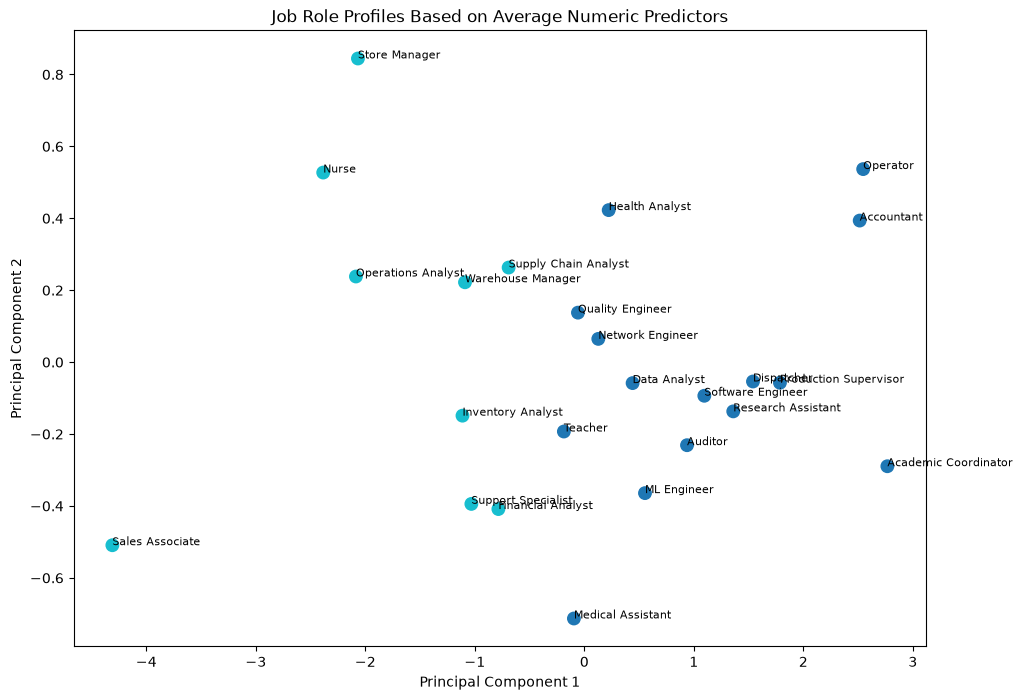

In [ ]:
clusters = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit_predict(X_scaled)

# Reduce the numeric averages to two dimensions for plotting
points = PCA(n_components=2).fit_transform(X_scaled)

plt.figure(figsize=(11, 8))
plt.scatter(points[:, 0], points[:, 1], c=clusters, cmap="tab10", s=80)

for i, job_role in enumerate(role_data.index):
    plt.annotate(job_role, (points[i, 0], points[i, 1]), fontsize=8)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Job Role Profiles Based on Average Numeric Predictors")
plt.show()

### Average profile of each cluster
Mean routine task %, creativity requirement and tasks automated % for the job roles in each cluster, which describes what each cluster represents.

In [ ]:
role_profiles = role_data.copy()
role_profiles["Cluster"] = clusters

display(role_profiles.groupby("Cluster")[numeric_predictors].mean().round(1))

,Routine_Task_Percentage,Creativity_Requirement,Tasks_Automated_Percentage
Cluster,,,
0,52.5,47.2,37.7
1,50.9,48.8,36.5
